# Analisis Dataset PUBG Mobile
 mengolah dataset PUBG Mobile untuk memprediksi `Win` (0 = tidak menang, 1 = menang). Karena target berupa dua kelas, model yang digunakan adalah Gradient Boosting Classifier. Evaluasi menggunakan Accuracy, Precision, Recall, F1-score, laporan klasifikasi, dan Confusion Matrix.


## 1. Import library

In [1]:
# Library untuk mengolah data dan membuat grafik
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk membagi data, membuat model, dan mengevaluasi klasifikasi
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)


## 2. Data loading

In [2]:
# Baca dataset utama
df = pd.read_csv("PUBG_Mobile.csv")

print("Ukuran dataset:", df.shape)
df.head()

Ukuran dataset: (2500, 16)


,Player_ID,Map,Tier,Kills,Damage_Dealt,Survival_Time_Minutes,Headshot_Percentage,Assists,Revives,Distance_Travelled_km,Longest_Kill_meters,Heals_Used,Boosts_Used,Match_Rank,Win,Favorite_Weapon
0,P1,Sanhok,Platinum,4,441.86,22.70,6.13,1,3,7.54,5.27,4,0,76,0,UMP45
1,P2,Livik,Conqueror,1,551.58,5.58,33.86,1,3,7.80,85.31,2,3,55,0,M762
2,P3,Miramar,Conqueror,5,414.27,14.64,5.88,1,3,2.31,240.73,7,6,35,0,SCAR-L
3,P4,Erangel,Ace,3,499.70,18.00,35.07,5,4,7.77,272.42,1,1,62,0,M762
4,P5,Erangel,Platinum,7,751.11,29.13,38.39,4,0,2.72,62.02,8,6,9,0,Groza


## 3. Data cleaning

In [3]:
# Cek informasi dan nilai kosong sebelum dibersihkan
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Player_ID              2500 non-null   str    
 1   Map                    2490 non-null   str    
 2   Tier                   2500 non-null   str    
 3   Kills                  2500 non-null   int64  
 4   Damage_Dealt           2485 non-null   float64
 5   Survival_Time_Minutes  2488 non-null   float64
 6   Headshot_Percentage    2500 non-null   float64
 7   Assists                2500 non-null   int64  
 8   Revives                2500 non-null   int64  
 9   Distance_Travelled_km  2500 non-null   float64
 10  Longest_Kill_meters    2500 non-null   float64
 11  Heals_Used             2500 non-null   int64  
 12  Boosts_Used            2500 non-null   int64  
 13  Match_Rank             2500 non-null   int64  
 14  Win                    2500 non-null   int64  
 15  Favorite_Weapon

In [4]:
print("Nilai kosong per kolom:")
print(df.isnull().sum())
print("Jumlah data duplikat:", df.duplicated().sum())

Nilai kosong per kolom:
Player_ID                 0
Map                      10
Tier                      0
Kills                     0
Damage_Dealt             15
Survival_Time_Minutes    12
Headshot_Percentage       0
Assists                   0
Revives                   0
Distance_Travelled_km     0
Longest_Kill_meters       0
Heals_Used                0
Boosts_Used               0
Match_Rank                0
Win                       0
Favorite_Weapon          10
dtype: int64
Jumlah data duplikat: 0


In [5]:
# Hapus baris duplikat dan baris yang targetnya kosong
df = df.drop_duplicates()
df = df.dropna(subset=["Win"])

# Isi nilai kosong numerik dengan median dan kategorikal dengan modus
kolom_angka = df.select_dtypes(include="number").columns
kolom_kategori = df.select_dtypes(include=["object", "str", "category"]).columns

for kolom in kolom_angka:
    df[kolom] = df[kolom].fillna(df[kolom].median())

for kolom in kolom_kategori:
    if df[kolom].isnull().any():
        df[kolom] = df[kolom].fillna(df[kolom].mode()[0])

print("Ukuran setelah cleaning:", df.shape)
print("Sisa nilai kosong:", df.isnull().sum().sum())


Ukuran setelah cleaning: (2500, 16)
Sisa nilai kosong: 0


## 4. EDA (Exploratory Data Analysis)

In [6]:
# Ringkasan statistik data
df.describe(include="all")

,Player_ID,Map,Tier,Kills,Damage_Dealt,Survival_Time_Minutes,Headshot_Percentage,Assists,Revives,Distance_Travelled_km,Longest_Kill_meters,Heals_Used,Boosts_Used,Match_Rank,Win,Favorite_Weapon
count,2500,2500,2500,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500
unique,2500,5,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8
top,P1,Sanhok,Crown,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,AKM
freq,1,528,335,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,345
mean,NaN,NaN,NaN,2.974000,403.694476,17.541132,32.142528,2.540000,2.019600,4.230532,172.513928,4.538400,3.497600,50.640400,0.010400,NaN
std,NaN,NaN,NaN,1.737622,148.991445,7.321274,15.686865,1.699869,1.425212,2.179639,99.996176,2.889129,2.289299,28.724769,0.101469,NaN
min,NaN,NaN,NaN,0.000000,0.000000,5.000000,5.030000,0.000000,0.000000,0.500000,5.080000,0.000000,0.000000,1.000000,0.000000,NaN
25%,NaN,NaN,NaN,2.000000,301.800000,11.120000,18.777500,1.000000,1.000000,2.330000,87.445000,2.000000,1.000000,26.000000,0.000000,NaN
50%,NaN,NaN,NaN,3.000000,407.140000,17.655000,32.100000,3.000000,2.000000,4.215000,167.185000,5.000000,3.000000,51.000000,0.000000,NaN
75%,NaN,NaN,NaN,4.000000,509.792500,23.990000,45.737500,4.000000,3.000000,6.140000,259.785000,7.000000,6.000000,76.000000,0.000000,NaN


Win
0    2474
1      26
Name: count, dtype: int64


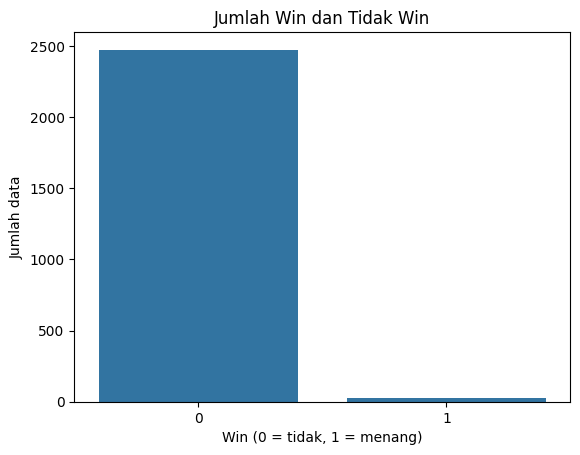

In [7]:
# Lihat jumlah data menang dan tidak menang
print(df["Win"].value_counts())
sns.countplot(data=df, x="Win")
plt.title("Jumlah Win dan Tidak Win")
plt.xlabel("Win (0 = tidak, 1 = menang)")
plt.ylabel("Jumlah data")
plt.show()

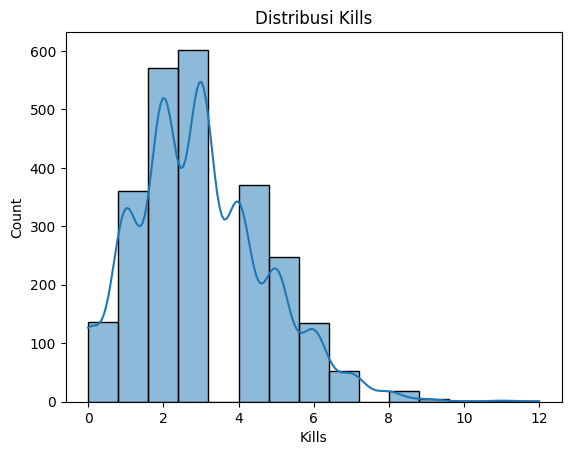

In [8]:
# Sebaran jumlah kill
sns.histplot(data=df, x="Kills", bins=15, kde=True)
plt.title("Distribusi Kills")
plt.show()

## 5. EXDA (eksplorasi data lanjutan)

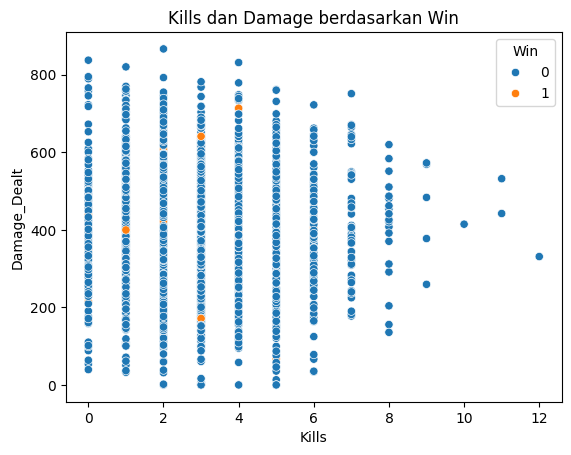

In [9]:
# Bandingkan kill dengan damage berdasarkan status kemenangan
sns.scatterplot(data=df, x="Kills", y="Damage_Dealt", hue="Win")
plt.title("Kills dan Damage berdasarkan Win")
plt.show()

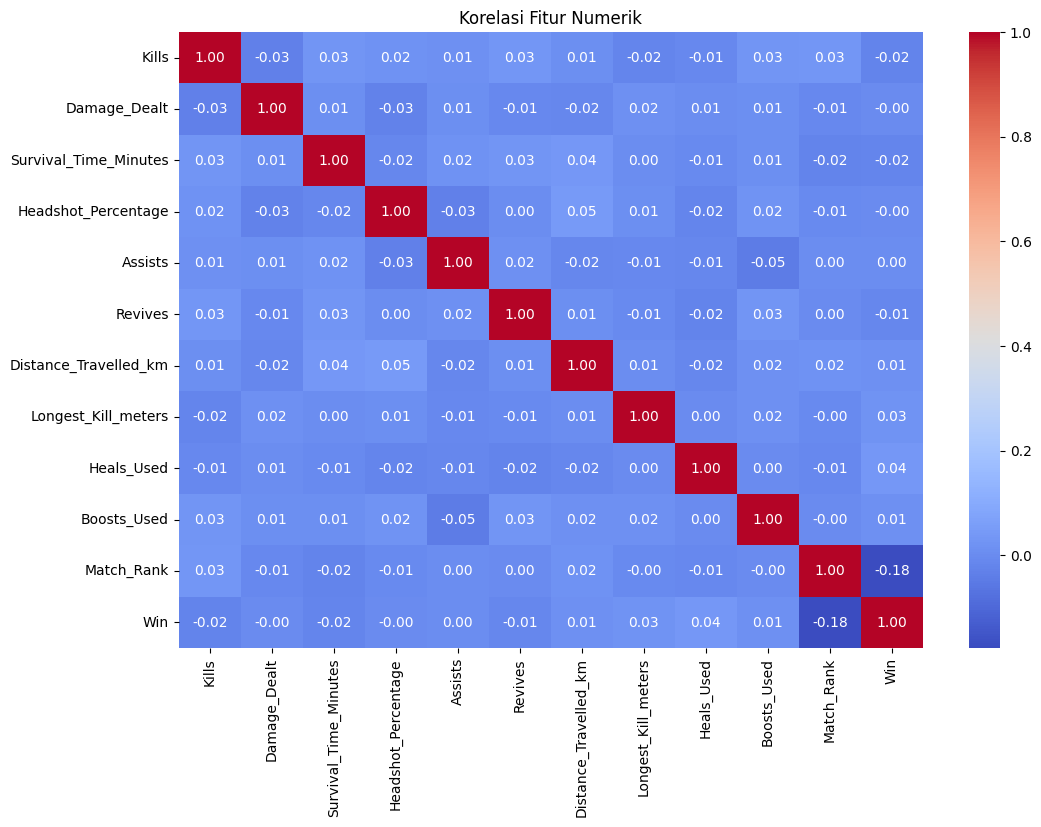

In [10]:
# Korelasi antar kolom numerik
plt.figure(figsize=(12, 8))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi Fitur Numerik")
plt.show()

## 6. Membagi data train dan test

In [11]:
# Win menjadi target yang ingin diprediksi. Player_ID hanya identitas pemain,
# sedangkan Match_Rank berpotensi mengandung informasi hasil akhir pertandingan.
X = df.drop(columns=["Win", "Player_ID", "Match_Rank"], errors="ignore")
y = df["Win"]

# Membagi data menjadi 80% training dan 20% testing.
# stratify menjaga perbandingan kelas Win tetap serupa di kedua bagian.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Data train:", X_train.shape)
print("Data test:", X_test.shape)
print("Distribusi Win pada data train:")
print(y_train.value_counts())
print("Distribusi Win pada data test:")
print(y_test.value_counts())

Data train: (2000, 13)
Data test: (500, 13)
Distribusi Win pada data train:
Win
0    1979
1      21
Name: count, dtype: int64
Distribusi Win pada data test:
Win
0    495
1      5
Name: count, dtype: int64


## 7. Modeling

In [12]:
# Pisahkan kolom kategori dan angka untuk preprocessing.
kolom_kategori = X_train.select_dtypes(include=["object", "str", "category"]).columns
kolom_angka = X_train.select_dtypes(include="number").columns

preprocessor = ColumnTransformer(
    transformers=[
        ("kategori", OneHotEncoder(handle_unknown="ignore"), kolom_kategori),
        ("angka", "passthrough", kolom_angka)
    ]
)

# Win adalah target klasifikasi (0 atau 1), jadi gunakan Classifier.
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", GradientBoostingClassifier(random_state=42))
])

# Beri bobot lebih pada kelas yang jumlahnya sedikit agar model memperhatikan kelas menang.
bobot_train = compute_sample_weight(class_weight="balanced", y=y_train)
model.fit(X_train, y_train, model__sample_weight=bobot_train)
print("Model selesai dilatih")


Model selesai dilatih


Metrik evaluasi yang digunakan adalah Accuracy, Precision, Recall, F1-score, laporan klasifikasi, dan Confusion Matrix. MAE, MSE, dan R² tidak digunakan karena tujuan analisis ini adalah klasifikasi menang atau tidak menang.


In [13]:
# Membuat prediksi untuk data testing yang belum dipakai saat pelatihan.
y_pred = model.predict(X_test)

# Menghitung metrik evaluasi klasifikasi.
akurasi = accuracy_score(y_test, y_pred)
presisi = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Accuracy :", round(akurasi, 4))
print("Precision:", round(presisi, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy : 0.978
Precision: 0.0
Recall   : 0.0
F1-score : 0.0

Laporan klasifikasi:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       495
           1       0.00      0.00      0.00         5

    accuracy                           0.98       500
   macro avg       0.49      0.49      0.49       500
weighted avg       0.98      0.98      0.98       500



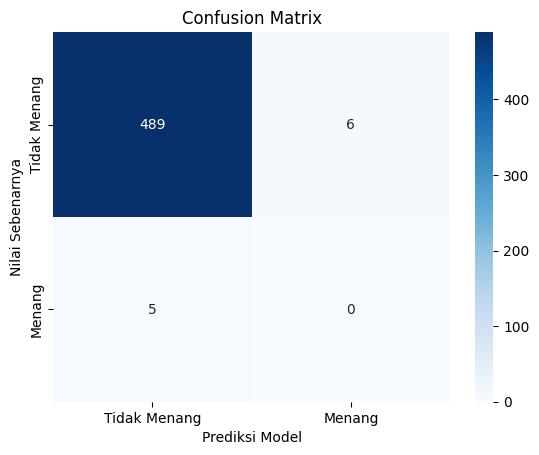

In [14]:
# Confusion matrix menunjukkan jumlah prediksi yang benar dan salah.
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Tidak Menang", "Menang"],
    yticklabels=["Tidak Menang", "Menang"]
)
plt.xlabel("Prediksi Model")
plt.ylabel("Nilai Sebenarnya")
plt.title("Confusion Matrix")
plt.show()

## 9. Kesimpulan evaluasi

Model yang digunakan adalah **Gradient Boosting Classifier** karena target `Win` berisi dua kelas, yaitu 0 (tidak menang) dan 1 (menang). Hasil evaluasi dilihat dari Accuracy, Precision, Recall, F1-score, dan Confusion Matrix.

Dataset ini memiliki jumlah kelas yang tidak seimbang: data tidak menang jauh lebih banyak daripada data menang. Karena itu, Accuracy saja belum cukup untuk menilai model. Perhatikan juga Precision, Recall, F1-score, dan jumlah prediksi benar atau salah pada Confusion Matrix, terutama untuk kelas menang. Pembobotan kelas digunakan saat pelatihan agar model lebih memperhatikan kelas yang jumlahnya sedikit.

Kesimpulan akhir perlu disesuaikan dengan angka evaluasi yang muncul setelah notebook dijalankan. Model belum tentu bagus hanya karena satu metrik memiliki nilai tinggi.